# Retail KPIs in SQL

Each section runs one file from `sql/` against `data/retail.db` (built by `python -m src.etl`). Fiscal years run December to November.

In [1]:
import os, sqlite3
import pandas as pd

os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
con = sqlite3.connect('data/retail.db')

def run(name):
    return pd.read_sql_query(open(f'sql/{name}.sql').read(), con)

pd.read_sql_query("SELECT name, type FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name", con)

,name,type
0,dim_customer,table
1,dim_product,table
2,fact_returns,table
3,fact_sales,table
4,v_orders,view


## 1. Headline KPIs by fiscal year

In [2]:
kpi = run('01_kpi_summary').set_index('fiscal_year')
kpi.loc['change'] = kpi.loc['FY2011'] / kpi.loc['FY2010'] - 1
kpi.round(3)

/var/folders/1p/8yx5y_mn771673kd0_4t9g6m0000gn/T/ipykernel_33702/2312487276.py:2: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  kpi.loc['change'] = kpi.loc['FY2011'] / kpi.loc['FY2010'] - 1
/var/folders/1p/8yx5y_mn771673kd0_4t9g6m0000gn/T/ipykernel_33702/2312487276.py:2: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  kpi.loc['change'] = kpi.loc['FY2011'] / kpi.loc['FY2010'] - 1


,revenue,orders,customers,avg_order_value,revenue_per_customer,orders_per_customer
fiscal_year,,,,,,
FY2010,9395871.280,19743.00,4239.000,475.910,1965.400,4.290
FY2011,9632333.240,18957.00,4293.000,508.110,1915.910,4.110
change,0.025,-0.04,0.013,0.068,-0.025,-0.042


Revenue grew while orders fell: the gain came from a higher average order value.

## 2. Monthly revenue with month-over-month and year-over-year growth (`LAG` window functions)

,order_month,revenue,orders,customers,avg_order_value,growth_mom,growth_yoy
18,2011-06,737558.98,1525,990,483.65,-0.0032,0.0590
19,2011-07,688144.79,1452,946,473.93,-0.0670,0.0871
20,2011-08,724196.76,1339,933,540.85,0.0524,0.0744
21,2011-09,1028313.80,1818,1259,565.63,0.4199,0.1830
22,2011-10,1103310.96,2005,1361,550.28,0.0729,0.0082
23,2011-11,1452112.69,2751,1660,527.85,0.3161,0.0158


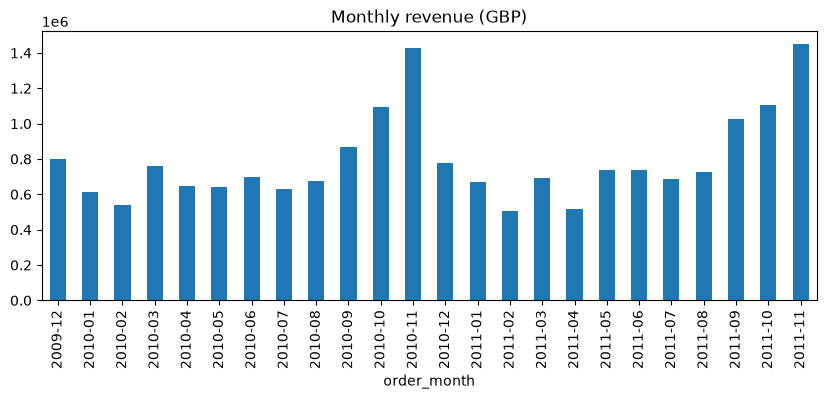

In [3]:
monthly = run('02_monthly_revenue')
ax = monthly.plot(x='order_month', y='revenue', kind='bar', figsize=(10, 3.5), legend=False, title='Monthly revenue (GBP)')
monthly.tail(6)

## 3. New vs returning customers

In [4]:
run('03_new_vs_returning').tail(6)

,order_month,new_customers,returning_customers,new_revenue,returning_revenue,returning_revenue_share
18,2011-06,108,882,82808.28,570456.64,0.8732
19,2011-07,101,845,42691.88,548911.91,0.9278
20,2011-08,107,826,44314.15,591200.23,0.9303
21,2011-09,188,1071,93170.67,845581.96,0.9008
22,2011-10,221,1140,97878.69,904447.87,0.9023
23,2011-11,191,1469,79903.35,1056630.65,0.9297


## 4. Cohort retention

In [5]:
ret = run('04_cohort_retention')
ret.pivot(index='cohort_month', columns='months_since', values='retention').iloc[:13, :13].style.format('{:.0%}', na_rep='').background_gradient(cmap='Blues', axis=None, vmax=0.5)

months_since,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,,
2009-12,100%,35%,33%,42%,38%,36%,38%,34%,34%,36%,42%,50%,38%
2010-01,100%,21%,32%,32%,27%,31%,27%,23%,29%,33%,31%,18%,23%
2010-02,100%,23%,23%,29%,25%,20%,19%,29%,26%,28%,11%,13%,15%
2010-03,100%,19%,23%,24%,23%,20%,25%,31%,28%,11%,12%,15%,20%
2010-04,100%,19%,19%,16%,18%,22%,28%,27%,11%,11%,7%,14%,14%
2010-05,100%,16%,17%,18%,18%,25%,21%,13%,6%,8%,11%,13%,15%
2010-06,100%,18%,19%,21%,23%,28%,13%,9%,8%,11%,10%,14%,15%
2010-07,100%,16%,18%,30%,29%,14%,11%,15%,15%,11%,14%,15%,13%
2010-08,100%,20%,29%,33%,17%,12%,10%,13%,14%,13%,13%,12%,15%


## 5. Top products

In [6]:
run('05_top_products')

,revenue_rank,stock_code,description,revenue,units,orders,share,cumulative_share
0,1,22423,REGENCY CAKESTAND 3 TIER,168162.42,13402,1929,0.0175,0.0175
1,2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,102236.34,36826,2132,0.0106,0.0281
2,3,47566,PARTY BUNTING,98526.75,18147,1657,0.0102,0.0383
3,4,85099B,JUMBO BAG RED RETROSPOT,91932.91,47266,2036,0.0095,0.0478
4,5,23166,MEDIUM CERAMIC TOP STORAGE JAR,81448.21,77826,233,0.0085,0.0563
5,6,22086,PAPER CHAIN KIT 50'S CHRISTMAS,58007.83,17241,1044,0.0060,0.0623
6,7,23084,RABBIT NIGHT LIGHT,57241.57,26435,867,0.0059,0.0683
7,8,84879,ASSORTED COLOUR BIRD ORNAMENT,56764.88,35032,1408,0.0059,0.0742
8,9,79321,CHILLI LIGHTS,51456.62,9840,630,0.0053,0.0795
9,10,22502,PICNIC BASKET WICKER SMALL,51408.77,1937,463,0.0053,0.0848


## 6. Revenue by country

In [7]:
run('06_country_revenue').head(10)

,country,customers,orders,revenue,avg_order_value,share
0,United Kingdom,3882,15874,6773525.86,426.71,0.8235
1,Netherlands,9,90,272161.32,3024.01,0.0331
2,EIRE,3,247,250184.20,1012.89,0.0304
3,Germany,94,427,199150.96,466.40,0.0242
4,France,84,358,175782.94,491.01,0.0214
5,Australia,8,44,132954.00,3021.68,0.0162
6,Spain,28,84,55096.19,655.91,0.0067
7,Switzerland,20,48,52537.29,1094.53,0.0064
8,Japan,8,19,37416.37,1969.28,0.0045
9,Belgium,23,98,37130.52,378.88,0.0045


## 7. RFM segments (`NTILE(5)` scores)

In [8]:
run('07_rfm_segments')

,segment,customers,avg_recency_days,avg_orders,avg_revenue,revenue,revenue_share,customer_share
0,1 Champions,1100,12.0,9.71,5115.44,5626980.72,0.6841,0.2562
1,2 Loyal,807,36.1,3.50,1307.56,1055198.56,0.1283,0.1880
2,3 New or promising,330,15.1,1.16,317.38,104735.21,0.0127,0.0769
3,4 At risk,668,148.1,3.34,1293.38,863978.93,0.1050,0.1556
4,5 Needs attention,338,49.2,1.09,394.79,133439.60,0.0162,0.0787
5,6 Lapsed,1050,215.6,1.08,419.68,440666.54,0.0536,0.2446


## 8. Return rate

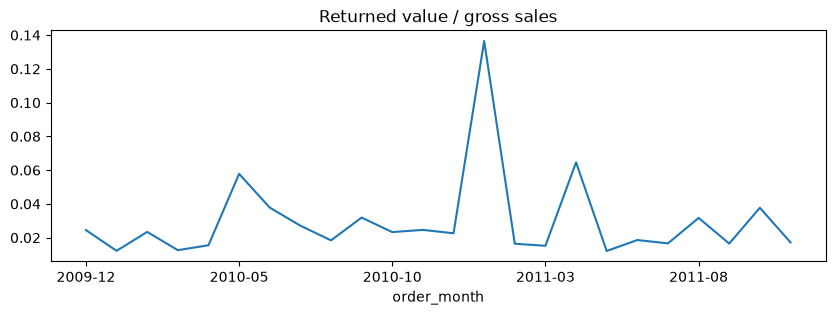

In [9]:
run('08_return_rate').plot(x='order_month', y='return_rate', figsize=(10, 3), legend=False, title='Returned value / gross sales');

## 9. Customer concentration

In [10]:
run('09_customer_concentration')

,decile,customers,min_revenue,revenue,share,cumulative_share
0,1,430,3415.30,4983466.64,0.6059,0.6059
1,2,430,1957.10,1106480.49,0.1345,0.7404
2,3,430,1305.33,681854.10,0.0829,0.8233
3,4,429,895.18,463571.81,0.0564,0.8797
4,5,429,646.30,325552.19,0.0396,0.9193
5,6,429,468.41,238763.50,0.0290,0.9483
6,7,429,337.74,170579.78,0.0207,0.9690
7,8,429,242.35,126826.63,0.0154,0.9844
8,9,429,152.88,83422.47,0.0101,0.9946
9,10,429,2.90,44481.95,0.0054,1.0000
